# Jour 4 — Validation des clusters

**Projet final « Apprentissage non supervisé » — Segmentation de clientèle bancaire**

**Objectifs du jour (Chapitre 4)**

| Partie | Contenu |
|---|---|
| A | Indices **internes** : silhouette, Davies-Bouldin, Dunn — toutes les méthodes, plusieurs valeurs de k |
| B | Indices **externes** par rapport à `y` : ARI, NMI, homogénéité, complétude, V-mesure |
| C | Étude de **stabilité** : 20 graines et bootstrap |
| D | Tableau de synthèse et **choix de la solution finale** |

C'est le seul notebook où la vérité terrain `y` est utilisée, et uniquement pour **évaluer** des partitions déjà construites.

In [1]:
# Mise en forme : toutes les bordures sur tous les tableaux du notebook
from IPython.display import HTML, display
display(HTML("<style>table, th, td {border: 1px solid #333 !important; border-collapse: collapse !important;} th, td {padding: 4px 8px !important;}</style>"))

In [2]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, davies_bouldin_score, adjusted_rand_score,
                             normalized_mutual_info_score, homogeneity_completeness_v_measure,
                             pairwise_distances)

from src.config import SEED, FIG, TAB, LAB, GOWER_CACHE
from src import preprocessing as pp
from src.clustering_utils import gower_matrix, dunn_index

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)

d = pp.prepare_all()
X_a, X_mixed, y = d["X_a"], d["X_mixed"], d["y"]
X = X_a.values
n = len(X)
D_euc = pairwise_distances(X)
D_gow = gower_matrix(X_mixed, cache=GOWER_CACHE)

# Toutes les partitions construites aux Jours 2 et 3
P = pd.concat([pd.read_csv(LAB / "partitions_j2.csv", index_col=0),
               pd.read_csv(LAB / "partitions_j3.csv", index_col=0)], axis=1)
assert (P.index == X_a.index).all()
print(f"{P.shape[1]} partitions à évaluer sur {n} clients")

NAMES = {"kmeans": "K-means", "kmedoids": "K-medoids (Gower)", "kprototypes": "K-prototypes", "gmm": "GMM",
         "ward": "CAH Ward", "cah_gower": "CAH moyen (Gower)", "cah_single": "CAH single",
         "cah_complete": "CAH complete", "cah_average": "CAH average", "dbscan": "DBSCAN"}

34 partitions à évaluer sur 4000 clients


# Partie A — Indices internes
Ils jugent une partition **sans information extérieure**, sur deux critères : la **compacité** (les membres d'un cluster sont proches) et la **séparation** (les clusters sont éloignés les uns des autres).

| Indice | Définition | Lecture |
|---|---|---|
| **Silhouette** | pour chaque point, $s = \dfrac{b - a}{\max(a, b)}$, où $a$ = distance moyenne aux points de son cluster et $b$ = distance moyenne aux points du cluster voisin le plus proche ; on fait la moyenne des $s$ | entre −1 et 1, **plus haut = mieux** |
| **Davies-Bouldin** | moyenne, sur les clusters, du pire rapport (dispersion interne de deux clusters) / (distance entre leurs centres) | ≥ 0, **plus bas = mieux** |
| **Dunn** | (plus petite distance entre deux clusters) / (plus grand diamètre d'un cluster) | ≥ 0, **plus haut = mieux** ; très sensible aux points extrêmes |

La silhouette est calculée dans les deux espaces (euclidien et Gower) pour ne favoriser aucune famille de méthodes. L'indice de Dunn est une **implémentation personnelle** (`src/clustering_utils.py`).

In [3]:
def internal_indices(labels):
    """Indices internes d'une partition (le bruit DBSCAN, étiqueté -1, est exclu)."""
    labels = np.asarray(labels)
    m = labels >= 0
    lab = labels[m]
    sizes = np.bincount(lab)
    sizes = sizes[sizes > 0]
    return {
        "nb clusters": len(sizes),
        "plus petit cluster (%)": 100 * sizes.min() / n,
        "silhouette eucl.": silhouette_score(X[m], lab),
        "silhouette Gower": silhouette_score(D_gow[np.ix_(m, m)], lab, metric="precomputed"),
        "Davies-Bouldin": davies_bouldin_score(X[m], lab),
        "Dunn": dunn_index(D_euc[np.ix_(m, m)], lab),
    }

def split_name(col):
    key, _, k = col.rpartition("_k")
    return (NAMES[key], int(k)) if key else (NAMES[col], None)

rows = []
for col in P.columns:
    method, k = split_name(col)
    rows.append({"partition": col, "méthode": method, **internal_indices(P[col].values)})
internal = pd.DataFrame(rows)
internal.to_csv(TAB / "04_indices_internes.csv", index=False)
internal.drop(columns="partition").style.format(precision=3).format({"plus petit cluster (%)": "{:.1f}"}).hide(axis="index")

méthode,nb clusters,plus petit cluster (%),silhouette eucl.,silhouette Gower,Davies-Bouldin,Dunn
K-means,2,33.8,0.236748,0.233115,1.882268,0.038009
K-means,3,14.2,0.185603,0.174976,1.917559,0.065288
K-means,4,7.9,0.182093,0.120695,1.841732,0.032644
K-means,5,5.9,0.199496,0.102398,1.702641,0.036580
K-means,6,5.8,0.146414,0.095679,1.872661,0.008079
K-medoids (Gower),2,45.5,0.110528,0.180106,2.539247,0.024600
K-medoids (Gower),3,26.8,0.039267,0.111181,3.731248,0.019526
K-medoids (Gower),4,21.8,0.042478,0.103442,3.860113,0.007945
K-medoids (Gower),5,11.8,0.033394,0.113080,3.426658,0.019201
K-medoids (Gower),6,10.4,0.014138,0.106236,3.921939,0.026147


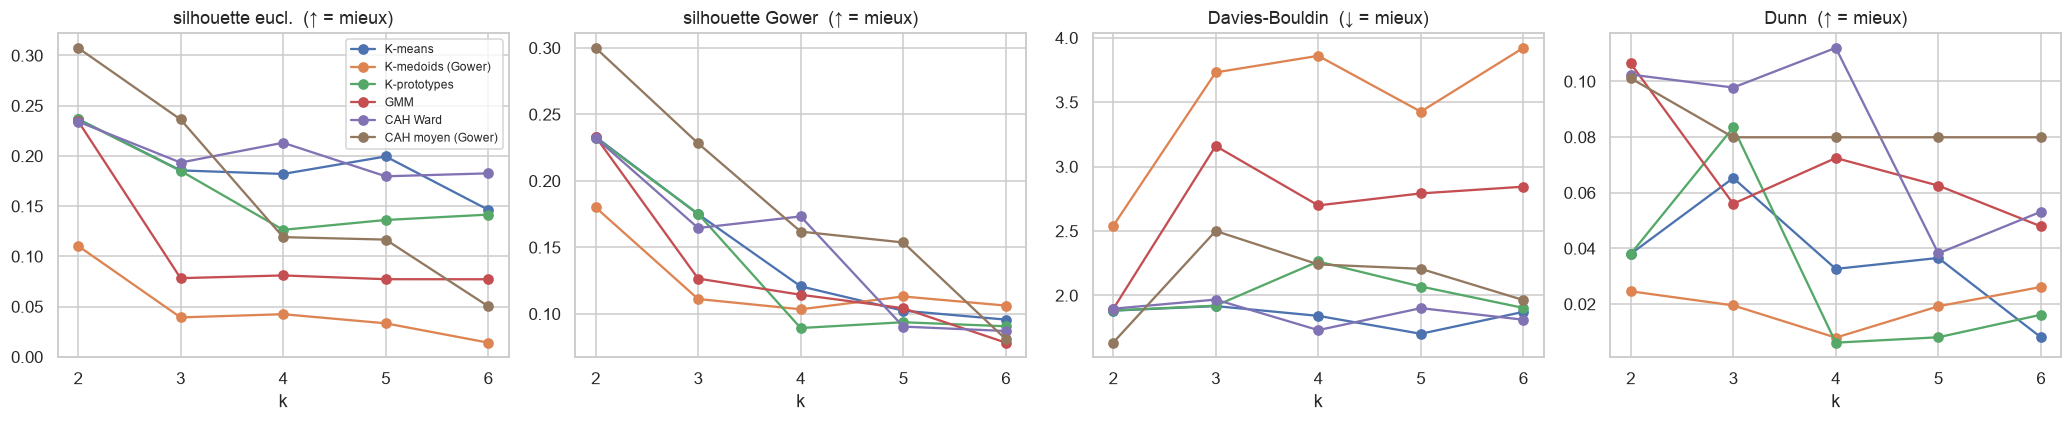

In [4]:
main = ["K-means", "K-medoids (Gower)", "K-prototypes", "GMM", "CAH Ward", "CAH moyen (Gower)"]
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, (idx, sense) in zip(axes, [("silhouette eucl.", "↑"), ("silhouette Gower", "↑"), ("Davies-Bouldin", "↓"), ("Dunn", "↑")]):
    for mth in main:
        sub = internal[internal["méthode"] == mth]
        ax.plot(sub["nb clusters"], sub[idx], "o-", label=mth)
    ax.set_title(f"{idx}  ({sense} = mieux)"); ax.set_xlabel("k"); ax.set_xticks(range(2, 7))
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "04_indices_internes.png", bbox_inches="tight"); plt.show()

**Lecture des indices internes.**
- **k = 2 est la structure la plus nette** pour presque toutes les méthodes (silhouette ≈ 0,23–0,24). K-means, K-prototypes, GMM et Ward trouvent la même coupure.
- Pour k = 3 et 4, **Ward** est la méthode qui se dégrade le moins : meilleure silhouette euclidienne (0,19 puis 0,21), Davies-Bouldin le plus bas à k = 4 (1,73) et meilleur indice de Dunn.
- **K-medoids (Gower)** et **GMM** (pour k ≥ 3) sont nettement en retrait sur tous les indices.
- **Attention aux fausses bonnes notes** : les liens *single*, *average*, *complete* et la CAH sur Gower obtiennent les silhouettes les plus hautes du tableau… avec un cluster qui contient plus de 85 % des clients. Leur « plus petit cluster » pèse moins de 4 %. Ces partitions isolent des atypiques, elles ne segmentent pas. Même remarque pour DBSCAN.
- Les valeurs absolues restent **modestes** (silhouette < 0,25) : les segments se chevauchent, comme l'annonçaient les projections du Jour 1. C'est normal pour des données de clientèle.

# Partie B — Indices externes (par rapport à `y`)
On compare maintenant chaque partition à la variable `y` (souscription oui / non), que les algorithmes n'ont jamais vue.

| Indice | Idée | Valeurs |
|---|---|---|
| **ARI** (indice de Rand ajusté) | proportion de paires de clients classées de la même façon, corrigée du hasard | 0 = hasard, 1 = accord parfait |
| **NMI** | information mutuelle entre partition et `y`, normalisée | 0 à 1 |
| **Homogénéité** | chaque cluster ne contient-il qu'une seule classe de `y` ? | 0 à 1 |
| **Complétude** | tous les clients d'une même classe sont-ils dans le même cluster ? | 0 à 1 |
| **V-mesure** | moyenne harmonique homogénéité / complétude | 0 à 1 |

**Précaution de lecture.** `y` a deux classes très déséquilibrées (11 % de « oui »). Une segmentation de clientèle n'a aucune raison de reproduire ce découpage : on s'attend à des valeurs **faibles**. Ces indices servent ici à comparer les méthodes entre elles et à vérifier que les segments ont un lien avec le comportement de souscription. Pour le lire plus concrètement, on ajoute le **taux de souscription** du segment le moins et le plus réceptif.

In [5]:
y_bin = (y == "yes").astype(int).values
rows = []
for col in P.columns:
    lab = P[col].values
    h, c, v = homogeneity_completeness_v_measure(y_bin, lab)
    rates = pd.Series(y_bin).groupby(lab).mean()
    rates = rates[rates.index >= 0]
    rows.append({"partition": col, "méthode": split_name(col)[0], "nb clusters": int((np.unique(lab) >= 0).sum()),
                 "ARI": adjusted_rand_score(y_bin, lab), "NMI": normalized_mutual_info_score(y_bin, lab),
                 "homogénéité": h, "complétude": c, "V-mesure": v,
                 "taux souscr. min (%)": 100 * rates.min(), "taux souscr. max (%)": 100 * rates.max()})
external = pd.DataFrame(rows)
external.to_csv(TAB / "04_indices_externes.csv", index=False)
external.drop(columns="partition").style.format(precision=3).format(
    {"taux souscr. min (%)": "{:.1f}", "taux souscr. max (%)": "{:.1f}"}).hide(axis="index")

méthode,nb clusters,ARI,NMI,homogénéité,complétude,V-mesure,taux souscr. min (%),taux souscr. max (%)
K-means,2,0.104376,0.059348,0.083539,0.046022,0.059348,5.6,22.4
K-means,3,0.095807,0.046397,0.085651,0.031816,0.046397,4.9,24.9
K-means,4,0.056570,0.037360,0.081051,0.024275,0.037360,4.1,25.0
K-means,5,0.088640,0.044996,0.102056,0.028861,0.044996,3.7,39.6
K-means,6,0.036719,0.033623,0.092841,0.020529,0.033623,4.6,39.7
K-medoids (Gower),2,-0.003102,0.034497,0.050989,0.026066,0.034497,5.0,16.5
K-medoids (Gower),3,0.014908,0.018208,0.037168,0.012058,0.018208,6.3,19.6
K-medoids (Gower),4,0.001609,0.015930,0.039245,0.009993,0.015930,4.4,19.3
K-medoids (Gower),5,0.016732,0.025239,0.068031,0.015494,0.025239,4.7,22.6
K-medoids (Gower),6,0.000870,0.015263,0.045368,0.009175,0.015263,4.2,20.8


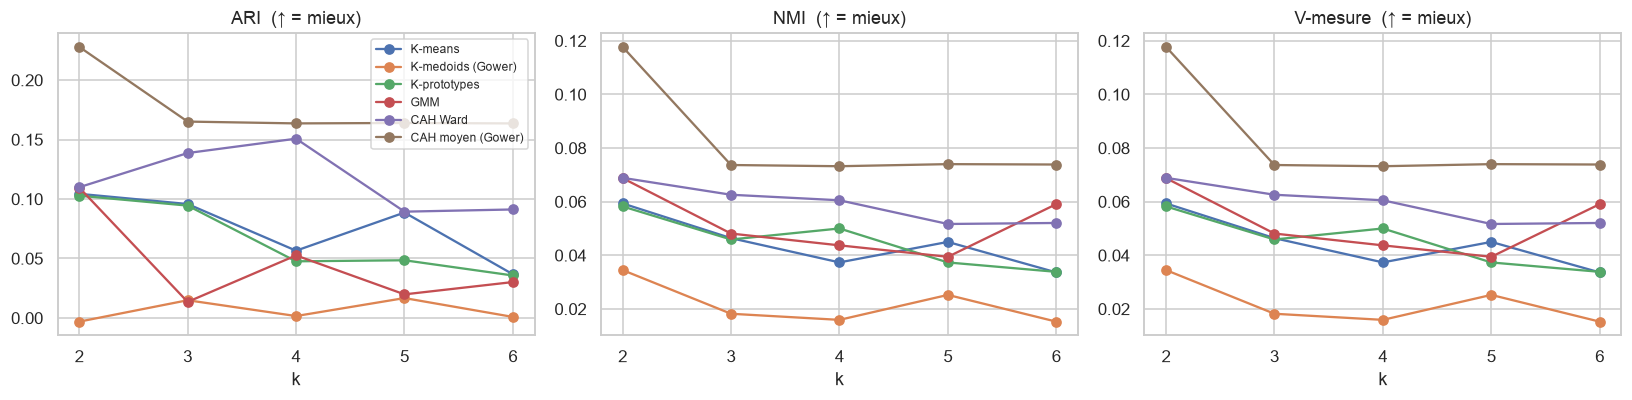

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, idx in zip(axes, ["ARI", "NMI", "V-mesure"]):
    for mth in main:
        sub = external[external["méthode"] == mth]
        ax.plot(sub["nb clusters"], sub[idx], "o-", label=mth)
    ax.set_title(f"{idx}  (↑ = mieux)"); ax.set_xlabel("k"); ax.set_xticks(range(2, 7))
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "04_indices_externes.png", bbox_inches="tight"); plt.show()

**Lecture des indices externes.**
- Comme prévu, les valeurs sont faibles (ARI < 0,25) : **les segments ne sont pas un classifieur de `y`**, et ce n'est pas leur rôle.
- Elles ne sont pourtant pas nulles : les segments séparent des clients dont le taux de souscription va de **4–6 %** à **40 % et plus**, alors que la moyenne est de 11 %. La segmentation est donc **utile pour le ciblage**.
- Pour les partitions équilibrées, l'**homogénéité** est supérieure à la **complétude** : les souscripteurs sont répartis dans plusieurs segments, ce qui pénalise la complétude.
- Parmi les méthodes équilibrées, **Ward** obtient les meilleurs ARI / NMI / V-mesure pour k = 3 et 4. **K-medoids (Gower)** est proche de zéro : ses groupes n'ont pas de lien avec la souscription.
- Les partitions « niches » (CAH sur Gower, liens *complete*) ont un bon ARI parce qu'elles isolent le petit groupe des anciens succès, très souscripteur. Information précieuse, mais qui ne décrit que 3 % de la clientèle.

# Partie C — Étude de stabilité
Une bonne segmentation ne doit pas dépendre du hasard. Deux tests, mesurés par l'**ARI entre exécutions** (1 = partitions identiques) :
1. **20 graines** : K-means est relancé 20 fois avec une seule initialisation aléatoire à chaque fois → sensibilité à l'**initialisation**.
2. **Bootstrap** : 20 rééchantillons tirés avec remise ; on reclasse chaque rééchantillon et on compare à la partition de référence sur les mêmes clients → sensibilité aux **données**.

Le bootstrap est appliqué à K-means et à Ward (Ward est déterministe : le test des graines ne le concerne pas).

In [7]:
N_RUNS, B = 20, 20
rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, n, n) for _ in range(B)]          # mêmes rééchantillons pour toutes les méthodes

stab_rows, seed_detail = [], []
for k in range(2, 7):
    # 1) 20 graines, une seule initialisation par exécution
    runs = [KMeans(n_clusters=k, n_init=1, random_state=s).fit_predict(X) for s in range(N_RUNS)]
    aris = [adjusted_rand_score(runs[i], runs[j]) for i in range(N_RUNS) for j in range(i + 1, N_RUNS)]
    seed_detail += [{"k": k, "ARI": a} for a in aris]
    # 2) bootstrap
    ref_km = P[f"kmeans_k{k}"].values
    ref_wd = P[f"ward_k{k}"].values
    b_km = [adjusted_rand_score(ref_km[ib], KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X[ib])) for ib in boot_idx]
    b_wd = [adjusted_rand_score(ref_wd[ib], AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X[ib])) for ib in boot_idx]
    stab_rows.append({"k": k, "K-means graines : ARI moyen": np.mean(aris), "K-means graines : ARI min": np.min(aris),
                      "K-means bootstrap : ARI moyen": np.mean(b_km), "K-means bootstrap : écart-type": np.std(b_km),
                      "Ward bootstrap : ARI moyen": np.mean(b_wd), "Ward bootstrap : écart-type": np.std(b_wd)})
stab = pd.DataFrame(stab_rows)
stab.to_csv(TAB / "04_stabilite.csv", index=False)
stab.round(3)

,k,K-means graines : ARI moyen,K-means graines : ARI min,K-means bootstrap : ARI moyen,K-means bootstrap : écart-type,Ward bootstrap : ARI moyen,Ward bootstrap : écart-type
0,2,0.882,0.336,0.997,0.003,0.987,0.022
1,3,0.691,0.347,0.976,0.076,0.956,0.037
2,4,0.787,0.606,0.715,0.249,0.932,0.086
3,5,0.774,0.495,0.648,0.211,0.861,0.023
4,6,0.730,0.408,0.971,0.013,0.713,0.155


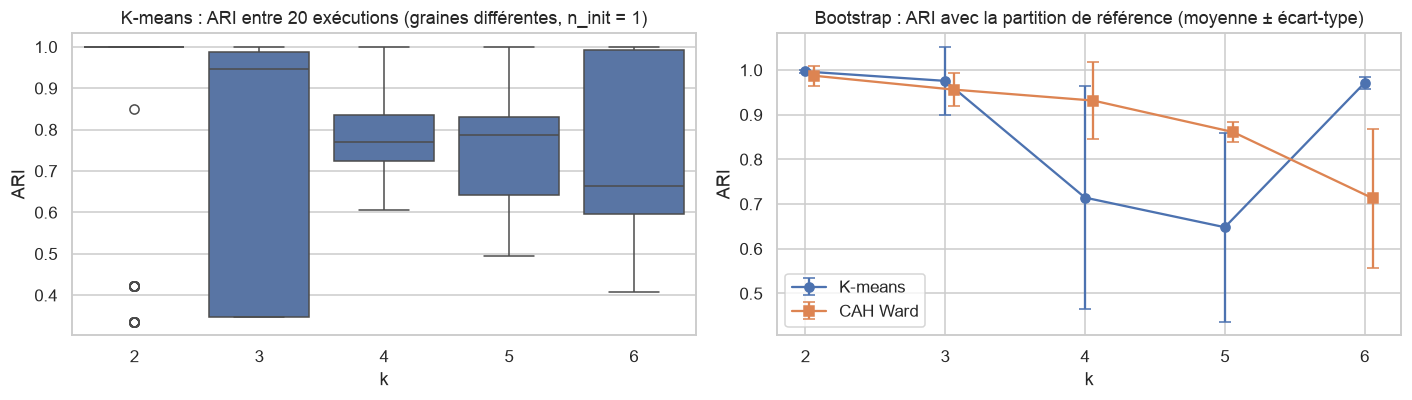

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.boxplot(data=pd.DataFrame(seed_detail), x="k", y="ARI", ax=axes[0], color="#4C72B0")
axes[0].set_title("K-means : ARI entre 20 exécutions (graines différentes, n_init = 1)")
axes[1].errorbar(stab["k"], stab["K-means bootstrap : ARI moyen"], yerr=stab["K-means bootstrap : écart-type"], fmt="o-", capsize=4, label="K-means")
axes[1].errorbar(stab["k"] + 0.06, stab["Ward bootstrap : ARI moyen"], yerr=stab["Ward bootstrap : écart-type"], fmt="s-", capsize=4, label="CAH Ward")
axes[1].set_title("Bootstrap : ARI avec la partition de référence (moyenne ± écart-type)")
axes[1].set_xlabel("k"); axes[1].set_ylabel("ARI"); axes[1].set_xticks(range(2, 7)); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG / "04_stabilite.png", bbox_inches="tight"); plt.show()

**Lecture de la stabilité.**
- **Graines (K-means, une seule initialisation)** : l'ARI moyen entre exécutions va de 0,69 à 0,88, avec des minimums autour de 0,35. Une initialisation unique peut donc tomber dans un mauvais optimum local : cela justifie `n_init = 10` (on garde la meilleure de 10 initialisations), utilisé partout ailleurs dans le projet.
- **Bootstrap, K-means** : très stable pour k = 2 (0,997) et k = 3 (0,98), mais **instable pour k = 4 et 5** (0,72 et 0,65, avec un écart-type de plus de 0,2) : selon l'échantillon tiré, K-means ne découpe pas les mêmes groupes.
- **Bootstrap, Ward** : la stabilité décroît régulièrement avec k, sans accident : 0,99 (k = 2), 0,96 (k = 3), **0,93 (k = 4)**, 0,86 (k = 5), 0,71 (k = 6).
- À **k = 4**, Ward est donc nettement plus stable que K-means (0,93 contre 0,72).

## D.1 Critères de sélection
Aucun indice ne suffit seul (on l'a vu avec les partitions dégénérées). La sélection se fait en quatre temps :

1. **Filtre métier** — le sujet demande 3 à 4 recommandations, une par segment : on retient **k = 3 ou 4**. De plus, chaque segment doit représenter **au moins 5 % des clients** pour justifier une action marketing dédiée.
2. **Classement sur les indices internes uniquement** — chaque candidat est classé sur 4 indices (silhouette euclidienne, silhouette Gower, Davies-Bouldin, Dunn) ; on calcule son **rang moyen** (1 = meilleur). La variable `y` n'intervient **pas** dans ce choix : sinon, constater ensuite que les segments séparent bien les souscripteurs serait un raisonnement circulaire.
3. **Contrôle de stabilité** du candidat en tête.
4. **Vérification a posteriori** avec les indices externes (ARI, V-mesure) : ils ne servent pas à choisir, seulement à vérifier que le choix a un sens vis-à-vis du comportement de souscription. On vérifie aussi que les ajouter au classement ne changerait pas le vainqueur.


In [9]:
synth = internal.merge(external.drop(columns=["méthode", "nb clusters"]), on="partition")
synth.to_csv(TAB / "04_synthese_complete.csv", index=False)

cand = synth[synth["nb clusters"].isin([3, 4]) & (synth["plus petit cluster (%)"] >= 5)
             & ~synth["méthode"].isin(["DBSCAN"])].copy()

def mean_rank(df, higher, lower=("Davies-Bouldin",)):
    """Rang moyen sur plusieurs indices (1 = meilleur) ; `lower` = indices où plus bas = mieux."""
    r = pd.concat([df[list(higher)].rank(ascending=False), df[list(lower)].rank(ascending=True)], axis=1)
    return r.mean(axis=1)

# Critère de choix : indices INTERNES seulement (y n'intervient pas)
cand["rang moyen (internes)"] = mean_rank(cand, ["silhouette eucl.", "silhouette Gower", "Dunn"])
# Contrôle : même classement en ajoutant les indices externes
cand["rang (internes + externes)"] = mean_rank(cand, ["silhouette eucl.", "silhouette Gower", "Dunn", "ARI", "V-mesure"])
cand = cand.sort_values("rang moyen (internes)")
show_cols = ["méthode", "nb clusters", "plus petit cluster (%)", "silhouette eucl.", "silhouette Gower",
             "Davies-Bouldin", "Dunn", "rang moyen (internes)", "ARI", "NMI", "V-mesure",
             "taux souscr. min (%)", "taux souscr. max (%)", "rang (internes + externes)"]
cand[show_cols].to_csv(TAB / "04_synthese_candidats.csv", index=False)
(cand[show_cols].style.format(precision=3)
     .format({"plus petit cluster (%)": "{:.1f}", "taux souscr. min (%)": "{:.1f}", "taux souscr. max (%)": "{:.1f}",
              "rang moyen (internes)": "{:.2f}", "rang (internes + externes)": "{:.2f}"})
     .background_gradient(subset=["rang moyen (internes)"], cmap="Greens_r").hide(axis="index"))


méthode,nb clusters,plus petit cluster (%),silhouette eucl.,silhouette Gower,Davies-Bouldin,Dunn,rang moyen (internes),ARI,NMI,V-mesure,taux souscr. min (%),taux souscr. max (%),rang (internes + externes)
CAH Ward,4,5.8,0.213139,0.173281,1.731009,0.112056,1.50,0.150734,0.060521,0.060521,5.1,39.7,1.50
K-prototypes,3,14.2,0.185185,0.175247,1.920731,0.083449,3.00,0.094470,0.045900,0.045900,4.9,24.9,3.67
K-means,3,14.2,0.185603,0.174976,1.917559,0.065288,3.25,0.095807,0.046397,0.046397,4.9,24.9,3.50
CAH Ward,3,15.7,0.193437,0.164580,1.968031,0.097796,3.25,0.138662,0.062581,0.062581,5.1,29.0,2.67
K-means,4,7.9,0.182093,0.120695,1.841732,0.032644,5.00,0.056570,0.037360,0.037360,4.1,25.0,5.50
GMM,4,14.3,0.081052,0.114375,2.699075,0.072483,6.25,0.052594,0.043714,0.043714,4.0,25.0,6.33
GMM,3,29.9,0.078346,0.126520,3.160015,0.056046,6.75,0.013507,0.048114,0.048114,4.6,23.0,6.67
K-prototypes,4,7.6,0.126450,0.089356,2.263823,0.006141,8.00,0.047631,0.050010,0.050010,5.8,45.2,7.00
K-medoids (Gower),3,26.8,0.039267,0.111181,3.731248,0.019526,8.75,0.014908,0.018208,0.018208,6.3,19.6,8.67
K-medoids (Gower),4,21.8,0.042478,0.103442,3.860113,0.007945,9.25,0.001609,0.015930,0.015930,4.4,19.3,9.50


In [10]:
best = cand.iloc[0]
print(f"Solution en tête (indices internes) : {best['méthode']} avec k = {best['nb clusters']}  (rang moyen = {best['rang moyen (internes)']:.2f})")
print(f"Second                              : {cand.iloc[1]['méthode']} avec k = {cand.iloc[1]['nb clusters']}  (rang moyen = {cand.iloc[1]['rang moyen (internes)']:.2f})")
best_ext = cand.sort_values("rang (internes + externes)").iloc[0]
same = (best_ext["partition"] == best["partition"])
print(f"Contrôle : avec ARI et V-mesure ajoutés, le vainqueur est {best_ext['méthode']} k = {best_ext['nb clusters']}"
      f" -> {'choix inchangé' if same else 'CHOIX DIFFÉRENT'}")

# Référence : la structure à 2 groupes (hors filtre métier), pour mesurer ce qu'on « paie » en passant à k = 4
ref2 = synth[synth["partition"].isin(["ward_k2", "kmeans_k2"])][[c for c in show_cols if "rang" not in c]]
ref2.style.format(precision=3).hide(axis="index")


Solution en tête (indices internes) : CAH Ward avec k = 4  (rang moyen = 1.50)
Second                              : K-prototypes avec k = 3  (rang moyen = 3.00)
Contrôle : avec ARI et V-mesure ajoutés, le vainqueur est CAH Ward k = 4 -> choix inchangé


méthode,nb clusters,plus petit cluster (%),silhouette eucl.,silhouette Gower,Davies-Bouldin,Dunn,ARI,NMI,V-mesure,taux souscr. min (%),taux souscr. max (%)
K-means,2,33.750,0.237,0.233,1.882,0.038,0.104,0.059,0.059,5.623,22.370
CAH Ward,2,34.575,0.234,0.232,1.897,0.102,0.110,0.069,0.069,5.082,22.993


## D.2 Décision : **CAH de Ward, k = 4**

**Justification du compromis.**

| Critère | Constat |
|---|---|
| Indices internes (critère de choix) | Premier au rang moyen sur les 4 indices internes : meilleure silhouette euclidienne, meilleur Davies-Bouldin et meilleur Dunn parmi les candidats ; 3ᵉ en silhouette Gower, à 0,002 de la meilleure. La silhouette (0,21) est proche de celle de la structure à 2 groupes (0,23) : on gagne deux segments sans perdre beaucoup en netteté. |
| Indices externes (vérification a posteriori) | Ils n'ont pas servi au choix. Ils le confirment : meilleur ARI parmi les candidats (0,15), V-mesure au niveau de la meilleure (0,061 contre 0,063)  ; taux de souscription de 5 % à 40 % selon le segment. Les ajouter au classement ne change pas le vainqueur. |
| Stabilité | ARI bootstrap de 0,93 pour Ward à k = 4, contre 0,72 pour K-means au même k. |
| Lisibilité | Partition emboîtée dans la coupure à 2 groupes : les 4 segments se présentent comme un raffinement de l'opposition principale. |
| Métier | 4 segments de taille suffisante (le plus petit : 5,8 % des clients) → 4 recommandations. |

**Ce qu'on accepte en échange.**
- k = 2 reste la structure statistiquement la plus nette ; k = 4 est un choix **guidé par le besoin métier**, validé (et non imposé) par les indices.
- Ward ne possède pas de fonction `predict` et ne passe pas à l'échelle de 41 000 clients (matrice $n^2$). Au Jour 5, on affectera donc chaque client de la population au **centre de segment le plus proche**.
- K-prototypes et K-means à k = 3 sont une alternative honnête (plus simples à déployer), mais Ward (k = 4) fait mieux sur trois des quatre indices internes.

**Méthodes écartées.** K-medoids sur Gower et GMM (structure faible, indices en retrait) ; liens *single / average / complete*, CAH sur Gower et DBSCAN (partitions déséquilibrées : utiles pour repérer des niches ou des atypiques, pas pour segmenter).

In [11]:
final_col = "ward_k4"
final = P[final_col].rename("segment")
final.to_csv(LAB / "segments_final_echantillon.csv")
print("Partition finale enregistrée :", final_col)
print(final.value_counts().sort_index().rename("effectif").to_frame().assign(
    pourcentage=lambda t: (100 * t["effectif"] / n).round(1),
    taux_souscription=(100 * pd.Series(y_bin, index=final.index).groupby(final).mean()).round(1)))

Partition finale enregistrée : ward_k4
         effectif  pourcentage  taux_souscription
segment                                          
0            2617         65.4                5.1
1             627         15.7               15.8
2             232          5.8               39.7
3             524         13.1               24.2


## Bilan du Jour 4
1. **Indices internes** : structure la plus nette à k = 2 ; au-delà, Ward résiste le mieux.
2. **Indices externes** : accord faible avec `y` (attendu), mais des écarts de taux de souscription très marqués entre segments.
3. **Stabilité** : k = 2 est quasi parfaitement stable ; la stabilité baisse quand k augmente, avec des différences entre méthodes.
4. **Solution retenue : CAH de Ward à 4 segments**, choisie sur les seuls indices internes et la stabilité, puis confirmée par les indices externes.